<img src="https://hilpisch.com/tpq_logo.png" alt="The Python Quants" width="35%" align="right" border="0"><br>

# Synthetic Financial Time Series

**WGAN-GP: Wasserstein Training with Gradient Penalty (PyTorch)**

&copy; Dr. Yves J. Hilpisch

<a href="https://tpq.io" target="_blank">https://tpq.io</a> | <a href="https://twitter.com/dyjh" target="_blank">@dyjh</a> | <a href="mailto:team@tpq.io">team@tpq.io</a>

## Imports & Settings

In [1]:
import os
import sys
import numpy as np
import pandas as pd
from pylab import plt, mpl

In [2]:
import torch

In [3]:
sys.path.insert(0, os.path.abspath('..'))
from synthts.data import load_eod, compute_log_returns, ReturnScaler
from synthts.wgangp import (WGANGenerator, Critic,
    train_wgangp, generate_samples)
from synthts.evaluate import (ks_test, ks_test_batch, pass_rate,
    describe_comparison, mse_sorted,
    plot_histograms, plot_sorted,
    plot_cumulative, plot_pvalue_histogram)

In [4]:
plt.style.use('seaborn-v0_8')
#mpl.rcParams['figure.dpi'] = 300
#mpl.rcParams['savefig.dpi'] = 300
mpl.rcParams['font.family'] = 'serif'

## Simple Example — Cubic Function

In [5]:
x = np.linspace(-2, 2, 500)
y = x ** 3
scaler = ReturnScaler()
y_ = scaler.fit_transform(y)

In [6]:
g = WGANGenerator(latent_dim=8, hidden_units=128, output_dim=1)
c = Critic(input_dim=1, hidden_units=128)

In [7]:
%%time
history = train_wgangp(
    g, c, y_.reshape(-1, 1),
    epochs=10001, batch_size=64,
    n_critic=1, lr_g=0.0002, lr_c=0.0002,
    latent_dim=8, seed=100
)

Epoch     0 | C: 8.9058 G: 0.0251 W: -0.0195
Epoch  1000 | C: 3.1906 G: -3.8434 W: -2.9397
Epoch  2000 | C: 8.7104 G: -5.0202 W: -4.3938
Epoch  3000 | C: -15.8840 G: 17.3973 W: 17.4289
Epoch  4000 | C: -3.1521 G: 5.7082 W: 3.2379
Epoch  5000 | C: -0.3492 G: 3.0606 W: 0.3769
CPU times: user 8.91 s, sys: 76 ms, total: 8.98 s
Wall time: 9.1 s


### Evaluation

In [8]:
data = pd.DataFrame({'real': y}, index=x)
N = 5
for i in range(N):
    samples = generate_samples(g, len(y), latent_dim=8)
    data[f'synth_{i:02d}'] = scaler.inverse_transform(samples)

In [9]:
data.describe().round(3)

,real,synth_00,synth_01,synth_02,synth_03,synth_04
count,500.000,500.000,500.000,500.000,500.000,500.000
mean,-0.000,-0.203,-0.199,-0.200,-0.199,-0.195
std,3.045,0.081,0.082,0.081,0.085,0.087
min,-8.000,-0.279,-0.279,-0.279,-0.279,-0.278
25%,-1.000,-0.261,-0.257,-0.255,-0.261,-0.256
50%,-0.000,-0.230,-0.228,-0.227,-0.228,-0.227
75%,1.000,-0.174,-0.168,-0.173,-0.163,-0.160
max,8.000,0.097,0.108,0.148,0.116,0.152


In [10]:
mse_sorted(data['real'].values, data['synth_00'].values)

np.float64(8.864402607288957)

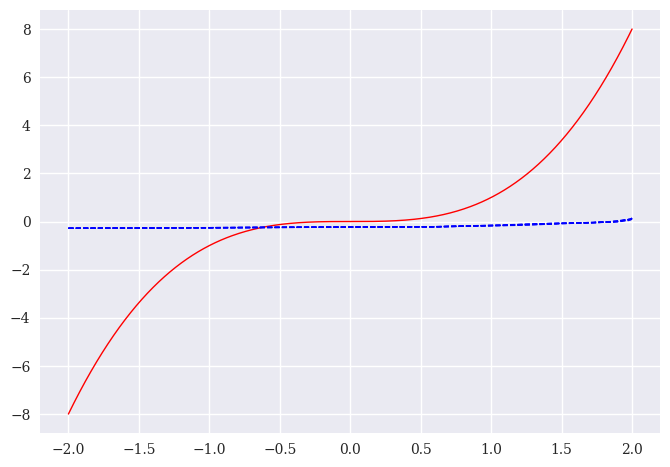

In [11]:
data.apply(np.sort).plot(
    style=['r'] + N * ['b--'], lw=1, legend=False);

## Financial Example — GLD Log-Returns

In [12]:
prices = load_eod(symbol='GLD', n_obs=2 * 252)
rets = compute_log_returns(prices)
scaler = ReturnScaler()
rets_ = scaler.fit_transform(rets)

In [13]:
g = WGANGenerator(latent_dim=8, hidden_units=128, output_dim=1)
c = Critic(input_dim=1, hidden_units=128)

In [14]:
%%time
history = train_wgangp(
    g, c, rets_.reshape(-1, 1),
    epochs=10001, batch_size=64,
    n_critic=1, lr_g=0.0002, lr_c=0.0002,
    latent_dim=8, seed=100
)

Epoch     0 | C: 9.2514 G: 0.1084 W: 0.0105
Epoch  1000 | C: 3.2016 G: -3.6877 W: -3.0470
Epoch  2000 | C: 8.3859 G: -5.4781 W: -4.9006
Epoch  3000 | C: -17.3805 G: 21.1243 W: 21.1658
Epoch  4000 | C: -3.9589 G: 5.2606 W: 4.7921
Epoch  5000 | C: -0.0996 G: 3.6409 W: 0.1556
CPU times: user 8.68 s, sys: 26.1 ms, total: 8.7 s
Wall time: 8.72 s


### Generating Synthetic Returns

In [15]:
data = pd.DataFrame({'real': rets})
N = 25
for i in range(N):
    samples = generate_samples(g, len(rets_), latent_dim=8)
    data[f'synth_{i:02d}'] = scaler.inverse_transform(samples)

In [16]:
describe_comparison(data, n_show=5)

,real,synth_00,synth_01,synth_02,synth_03
count,503.0000,503.0000,503.0000,503.0000,503.0000
mean,0.0014,0.0016,0.0015,0.0016,0.0016
std,0.0111,0.0008,0.0007,0.0008,0.0008
min,-0.0664,0.0007,0.0007,0.0007,0.0007
25%,-0.0044,0.0010,0.0010,0.0010,0.0010
50%,0.0018,0.0013,0.0013,0.0013,0.0014
75%,0.0082,0.0018,0.0017,0.0019,0.0019
max,0.0363,0.0053,0.0047,0.0054,0.0057


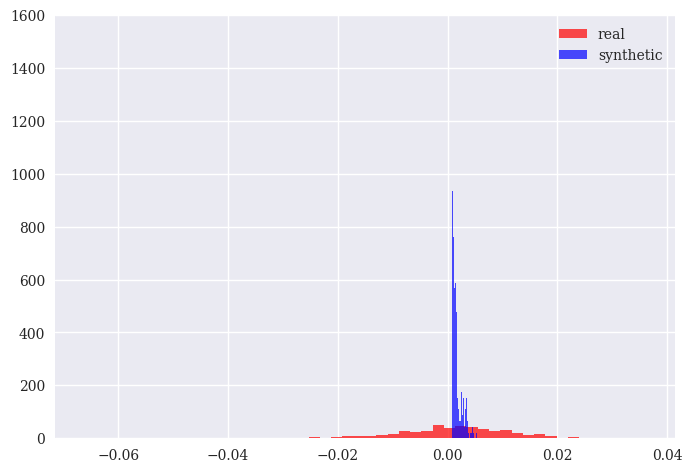

In [17]:
plot_histograms(data['real'].values, data['synth_00'].values);

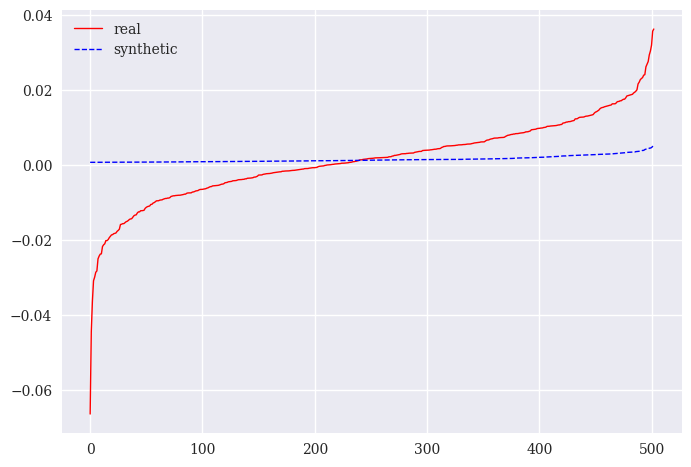

In [18]:
plot_sorted(data['real'].values, data['synth_00'].values);

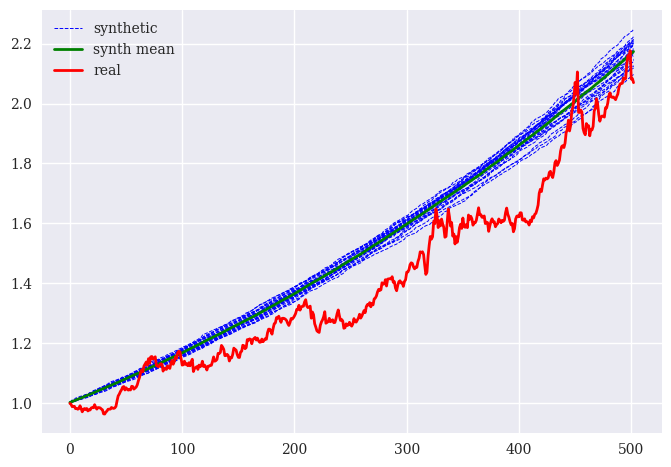

In [19]:
plot_cumulative(data, n_synth=N);

### Kolmogorov-Smirnov Test

In [20]:
synth_cols = [c for c in data.columns if c.startswith('synth')]
pvals = ks_test_batch(data['real'].values, data[synth_cols])
pvals.round(4)

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0.])

In [21]:
f'KS pass rate: {pass_rate(pvals):.0%}'

'KS pass rate: 0%'

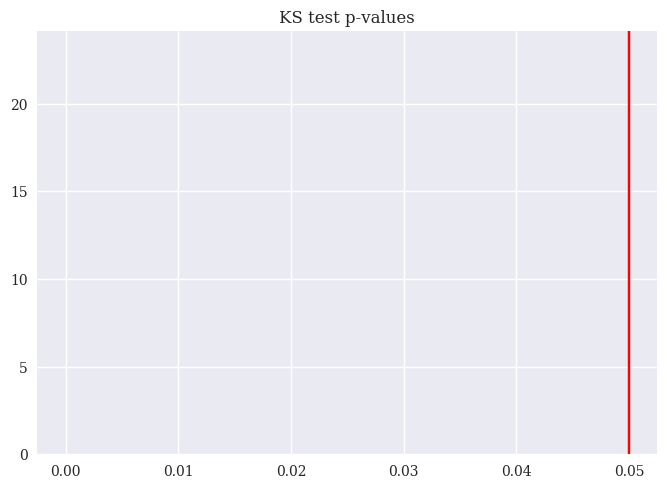

In [22]:
plot_pvalue_histogram(pvals);

<img src="https://hilpisch.com/tpq_logo.png" alt="The Python Quants" width="35%" align="right" border="0"><br>

<a href="https://tpq.io" target="_blank">https://tpq.io</a> | <a href="https://twitter.com/dyjh" target="_blank">@dyjh</a> | <a href="mailto:team@tpq.io">team@tpq.io</a>